# 04 – Neural entity-recognition comparators

BiLSTM–CRF and Biomedical Transformer are evaluated from their individual Validation predictions on the same 2,915 eligible gold entities.

In [1]:
from pathlib import Path
from typing import Iterable, Sequence
from collections import Counter
from itertools import combinations
import json
import math
import re
import sys
import textwrap
import unicodedata
import xml.etree.ElementTree as ET
import joblib
import torch
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import entropy
from scipy.spatial.distance import jensenshannon
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity
from matplotlib_inline.backend_inline import set_matplotlib_formats

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for _folder in ("artifacts", "figures/PNG", "figures/PDF", "Models", "Predictions", "Reports"):
    (PROJECT_ROOT / _folder).mkdir(parents=True, exist_ok=True)    # output folders of a fresh clone
SHARED_DATASET = PROJECT_ROOT / "dataset"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from core import ENTITY_TYPES, PREDICTION_COLUMNS
from analysis_tools import MODELS, FOCAL

BLUE, GOLD, INK = "#315C80", "#B47A19", "#252525"

In [3]:
set_matplotlib_formats("png", bbox_inches=None)
plt.ioff()
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("styler.render.max_elements", 100000)
mpl.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.size": 18,
        "axes.titlesize": 20,
        "figure.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#333333",
        "text.color": "#222222",
        "axes.labelcolor": "#222222",
        "xtick.color": "#333333",
        "ytick.color": "#333333",
        "axes.grid": False,
    }
)
assert "Times New Roman" in mpl.font_manager.findfont(
    "Times New Roman", fallback_to_default=False
)

In [4]:
def format_number(value: float, precision: int) -> str:
    """Format the display only; scientific values in exported CSV remain unchanged."""
    if pd.isna(value):
        return "N/A"
    if abs(value) < 0.5 * 10 ** (-precision):
        return "0" if precision == 0 else "0." + "0" * precision
    return f"{value:.{precision}f}".replace("-", "−")

In [5]:
def shared_root(project_root: Path) -> Path:
    root = (project_root / "dataset").resolve()
    if not (root / "Raw" / "ACQUISITION.json").exists():
        raise RuntimeError("Immutable shared dataset acquisition is missing.")
    return root

In [6]:
def load_processed(
    project_root: Path, split: str
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    shared = shared_root(project_root)
    sentences = pd.read_parquet(shared / "Processed" / f"{split}_sentences.parquet")
    entities = pd.read_parquet(shared / "Processed" / f"{split}_entities.parquet")
    tokens = pd.read_parquet(shared / "Processed" / f"{split}_tokens.parquet")
    return (sentences, entities, tokens)

In [7]:
def gold_for_metrics(entities: pd.DataFrame) -> pd.DataFrame:
    return entities.query("not discontinuous and offset_valid").copy()

In [8]:
analysis_split = "Development"
sentences, raw_entities, tokens = load_processed(PROJECT_ROOT, "validation")
gold = gold_for_metrics(raw_entities)
predictions = {
    model: pd.read_parquet(
        PROJECT_ROOT / "Predictions/Validation" / (MODELS[model] + ".parquet")
    )
    for model in ["BiLSTM-CRF", "Biomedical Transformer"]
}
for prediction in predictions.values():
    assert prediction.entity_id.is_unique
    assert set(prediction.sentence_id) <= set(sentences.sentence_id)
    assert not prediction.duplicated(
        ["sentence_id", "char_start", "char_end", "predicted_type"]
    ).any()

## Strict entity recognition

**Scientific question.** How accurately does each model detect and type exact spans?

In [9]:
gold_typed = set(
    gold[["sentence_id", "char_start", "char_end", "entity_type"]].itertuples(
        index=False, name=None
    )
)
gold_boundaries = {entity[:3] for entity in gold_typed}
quality_rows = []
for model, prediction in predictions.items():
    predicted_typed = set(
        prediction[["sentence_id", "char_start", "char_end", "predicted_type"]].itertuples(
            index=False, name=None
        )
    )
    predicted_boundaries = {entity[:3] for entity in predicted_typed}
    typed_true_positive = len(gold_typed & predicted_typed)
    boundary_true_positive = len(gold_boundaries & predicted_boundaries)
    subtype_scores = {}
    for kind in ENTITY_TYPES:
        actual = {entity for entity in gold_typed if entity[-1] == kind}
        emitted = {entity for entity in predicted_typed if entity[-1] == kind}
        denominator = len(actual) + len(emitted)
        subtype_scores[f"{kind} F1"] = (
            2 * len(actual & emitted) / denominator if denominator else 0.0
        )
    quality_rows.append(
        {
            "Model": model,
            "Split": analysis_split,
            "N": len(gold_typed),
            "Predictions": len(predicted_typed),
            "TP": typed_true_positive,
            "FP": len(predicted_typed) - typed_true_positive,
            "FN": len(gold_typed) - typed_true_positive,
            "Boundary P": (
                boundary_true_positive / len(predicted_boundaries)
                if predicted_boundaries
                else 0.0
            ),
            "Boundary R": (
                boundary_true_positive / len(gold_boundaries) if gold_boundaries else 0.0
            ),
            "Boundary F1": 2
            * boundary_true_positive
            / (len(gold_boundaries) + len(predicted_boundaries)),
            "Typed P": typed_true_positive / len(predicted_typed) if predicted_typed else 0.0,
            "Typed R": typed_true_positive / len(gold_typed),
            "Typed F1": 2 * typed_true_positive / (len(gold_typed) + len(predicted_typed)),
            "Macro-F1": float(np.mean(list(subtype_scores.values()))),
            **subtype_scores,
        }
    )
quality = pd.DataFrame(quality_rows)
predictive = quality[
    ["Model", "N", "Boundary F1", "Typed P", "Typed R", "Typed F1", "Macro-F1"]
]

In [10]:
result_table = predictive.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_04_predictive.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Model,N,Boundary F1,Typed P,Typed R,Typed F1,Macro-F1
BiLSTM-CRF,2915,0.8965,0.8646,0.7976,0.8298,0.6167
Biomedical Transformer,2915,0.9097,0.8362,0.8755,0.8554,0.6762


Biomedical Transformer has the highest development Typed F1 among the models in this table.

Typed F1 = 0.8554; Boundary F1 = 0.9097; Macro-F1 = 0.6762; eligible gold N = 2,915 for every compared model.

Boundary F1 ignores subtype; Typed F1 requires exact boundaries and the correct type.

**Scope.** These Validation predictions participated in model selection.

## Subtype balance

**Scientific question.** Does aggregate performance hide errors on brand or drug_n?

In [11]:
subtypes = quality[["Model", "N", "drug F1", "brand F1", "group F1", "drug_n F1"]]
result_table = subtypes.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_04_subtypes.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Model,N,drug F1,brand F1,group F1,drug_n F1
BiLSTM-CRF,2915,0.8832,0.4562,0.8589,0.2687
Biomedical Transformer,2915,0.9043,0.7603,0.8291,0.2112


Subtype scores reveal uneven performance concealed by micro-F1.

Four type-specific F1 values use the same strict matching rule.

Macro-F1 weights each subtype equally.

**Scope.** Rare-class estimates have fewer supporting annotations.

## Confidence validity

**Scientific question.** How well calibrated are accepted entity predictions?

In [12]:
def span_set(frame: pd.DataFrame, typed: bool = True, gold: bool = False) -> set:
    cols = ["sentence_id", "char_start", "char_end"]
    if typed:
        cols += ["entity_type" if gold else "predicted_type"]
    return set(frame[cols].itertuples(index=False, name=None))

In [13]:
def wilson(k, n):
    if n == 0:
        return (np.nan, np.nan)
    z = stats.norm.ppf(0.975)
    p = k / n
    d = 1 + z * z / n
    return (
        (p + z * z / (2 * n) - z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / d,
        (p + z * z / (2 * n) + z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / d,
    )

In [14]:
def calibration(gold, predictions, bins=(5, 10, 15, 20)):
    g = span_set(gold, gold=True)
    rows = []
    reliability = []
    risk = []
    for model, p in predictions.items():
        y = np.array(
            [
                int(k in g)
                for k in p[
                    ["sentence_id", "char_start", "char_end", "predicted_type"]
                ].itertuples(index=False, name=None)
            ]
        )
        confidence = p.calibrated_confidence.to_numpy(float)
        assert np.isfinite(confidence).all() and ((confidence >= 0) & (confidence <= 1)).all()
        if len(y):
            order = np.argsort(-confidence, kind="stable")
            prefix_risk = 1 - np.cumsum(y[order]) / np.arange(1, len(y) + 1)
            aurc = float(prefix_risk.mean())
        else:
            aurc = np.nan
        for nbins in bins:
            bid = np.minimum((confidence * nbins).astype(int), nbins - 1)
            ece = 0.0
            for b in range(nbins):
                selected = bid == b
                if selected.any():
                    acc = y[selected].mean()
                    conf = confidence[selected].mean()
                    n = int(selected.sum())
                    ece += n / max(len(y), 1) * abs(acc - conf)
                    if nbins == 10:
                        low, high = wilson(int(y[selected].sum()), n)
                        reliability.append(
                            {
                                "Model": model,
                                "Bin": b,
                                "N": n,
                                "Confidence": conf,
                                "Accuracy": acc,
                                "CI Low": low,
                                "CI High": high,
                            }
                        )
            rows.append(
                {
                    "Model": model,
                    "Accepted N": len(y),
                    "Bins": nbins,
                    "ECE": ece if len(y) else np.nan,
                    "Brier": np.mean((confidence - y) ** 2) if len(y) else np.nan,
                    "Discrete AURC": aurc,
                }
            )
        if len(y):
            order = np.argsort(-confidence, kind="stable")
            correct = np.cumsum(y[order])
            for coverage in np.arange(0.1, 1.01, 0.1):
                k = max(1, math.ceil(coverage * len(y)))
                tp = int(correct[k - 1])
                risk.append(
                    {
                        "Model": model,
                        "Coverage": k / len(y),
                        "Accepted N": k,
                        "Risk": 1 - tp / k,
                        "Selective Typed F1": 2 * tp / (k + len(g)),
                    }
                )
    return (pd.DataFrame(rows), pd.DataFrame(reliability), pd.DataFrame(risk))

In [15]:
calibration_rows, reliability, risk = calibration(gold, predictions)
calibration_main = calibration_rows.query("Bins == 10")
result_table = calibration_main.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_04_calibration.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Model,Accepted N,Bins,ECE,Brier,Discrete AURC
BiLSTM-CRF,2689,10,0.3010,0.2293,0.0524
Biomedical Transformer,3052,10,0.0887,0.1007,0.0377


Calibration is evaluated on accepted predictions and their exact typed correctness.

ECE uses ten equal-width bins; Brier uses every accepted prediction.

O-only has no accepted entities, so its calibration is not estimable.

**Scope.** Model-specific accepted universes differ; lower ECE alone does not imply better recognition.

## Errors and boundary failures

**Scientific question.** What kinds of false positives distinguish the models?

In [16]:
def error_partition(gold, predictions):
    g = span_set(gold, gold=True)
    gb = {s[:3] for s in g}
    type_map = {s[:3]: s[-1] for s in g}
    rows = []
    for m, p in predictions.items():
        counts = {
            "Exact typed": 0,
            "Wrong type": 0,
            "Overlong": 0,
            "Underlong": 0,
            "Shifted overlap": 0,
            "Spurious": 0,
        }
        by_sentence = {
            s: list(f[["char_start", "char_end"]].itertuples(index=False, name=None))
            for s, f in gold.groupby("sentence_id")
        }
        for key in span_set(p):
            s, a, b, t = key
            if key in g:
                category = "Exact typed"
            elif key[:3] in gb:
                category = "Wrong type"
            else:
                overlaps = [(c, d) for c, d in by_sentence.get(s, []) if max(a, c) < min(b, d)]
                if not overlaps:
                    category = "Spurious"
                else:
                    c, d = max(overlaps, key=lambda z: min(b, z[1]) - max(a, z[0]))
                    category = (
                        "Overlong"
                        if a <= c and b >= d
                        else "Underlong" if a >= c and b <= d else "Shifted overlap"
                    )
            counts[category] += 1
        assert sum(counts.values()) == len(span_set(p))
        rows += [
            {
                "Model": m,
                "Error category": k,
                "Count": v,
                "Prediction share": v / len(p) if len(p) else np.nan,
            }
            for k, v in counts.items()
        ]
    return pd.DataFrame(rows)

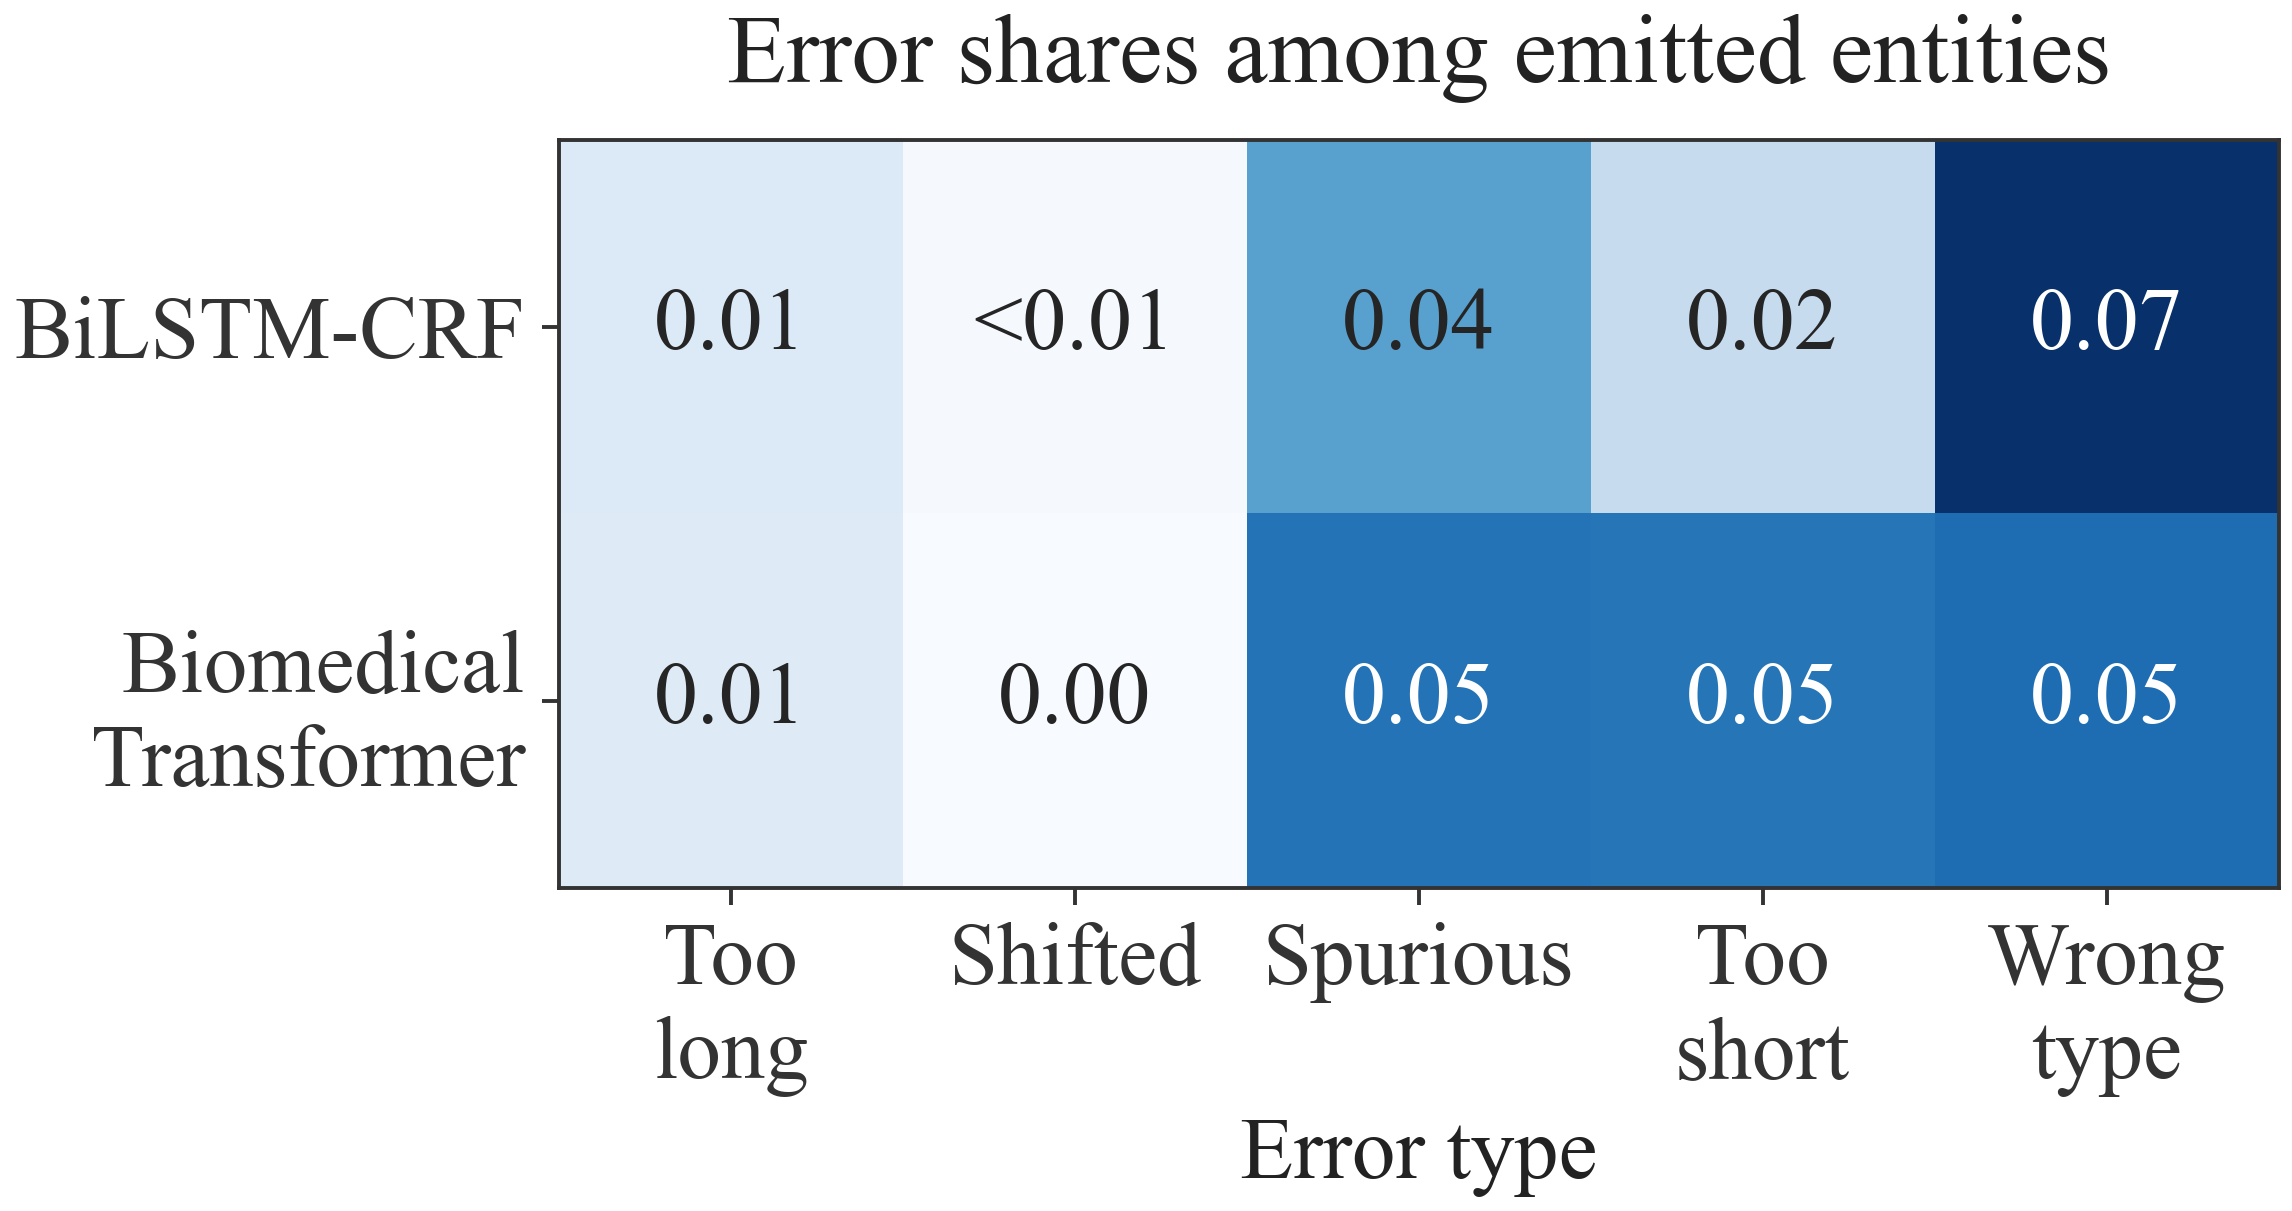

In [17]:
errors = error_partition(gold, predictions)
error_matrix = errors.query("`Error category` != 'Exact typed'")
plot_data = error_matrix.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.55, 3.4600000000000004), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
matrix = plot_data.pivot(index="Model", columns="Error category", values="Prediction share")
for axis in ("index", "columns"):
    labels = list(getattr(matrix, axis))
    order = (
        list(ENTITY_TYPES) + ["No exact span"]
        if set(ENTITY_TYPES) <= set(labels)
        else ["O", "B", "I", "E", "S"]
    )
    if set(labels) <= set(order):
        matrix = matrix.reindex(**{axis: [label for label in order if label in labels]})
values = matrix.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
assert not np.isinf(values).any()
signed = bool(len(finite) and finite.min() < 0)
colormap = mpl.colormaps["RdBu_r" if signed else "Blues"].copy()
colormap.set_bad("#E4E4E4")
heatmap = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=colormap,
    aspect="auto",
    **{"vmin": -1, "vmax": 1} if signed else {},
)
short_labels = {
    "Overlong": "Too\nlong",
    "Underlong": "Too\nshort",
    "Shifted overlap": "Shifted",
    "Wrong type": "Wrong\ntype",
}
ax.set_xticks(
    range(len(matrix.columns)),
    [short_labels.get(str(v), textwrap.fill(str(v), 11)) for v in matrix.columns],
)
ax.set_yticks(range(len(matrix)), [textwrap.fill(str(v), 16) for v in matrix.index])
for (row, column), value in np.ndenumerate(values):
    rgba = heatmap.cmap(heatmap.norm(value))
    luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
    if not np.isfinite(value):
        annotation = "N/A"
    elif "Prediction share" == "Count":
        annotation = f"{value:,.0f}"
    elif 0 < abs(value) < 0.005:
        annotation = ">−0.01" if value < 0 else "<0.01"
    else:
        annotation = f"{value:.2f}".replace("-", "−")
    ax.text(
        column,
        row,
        annotation,
        ha="center",
        va="center",
        fontsize=18,
        color="white" if np.isfinite(value) and luminance < 0.5 else INK,
    )
if np.isnan(values).any():
    assert "N/A: O-only emits no entities (N = 0)."
    fig.supxlabel(
        textwrap.fill("N/A: O-only emits no entities (N = 0).", 52), fontsize=18, color=INK
    )
ax.set_title("Error shares among emitted entities", fontsize=20, pad=12)
ax.set_xlabel("Error type")
ax.set_ylabel("")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(PROJECT_ROOT / "figures/PNG/pub_04_error_profile.png", dpi=350, facecolor="white")
fig.savefig(PROJECT_ROOT / "figures/PDF/pub_04_error_profile.pdf", dpi=350, facecolor="white")
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_04_error_profile_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

Every prediction is assigned to exactly one error category.

Five false-positive categories distinguish wrong type, long/short boundary, shifted overlap, and spurious span.

Each share is the category count divided by all emitted entities. Gray N/A cells mean a zero denominator for O-only; they are not zero error rates. Positive shares below 0.005 are labeled <0.01, not rounded to zero.

**Scope.** False negatives are outside this emitted-prediction partition. O-only misses every eligible gold entity; its recall and F1 are zero. For multiple overlapping gold spans, maximal overlap defines the diagnostic category.

## Seen and domain subgroups

**Scientific question.** Where is development performance weakest?

In [18]:
def normalize_surface(text: str) -> str:
    normalized = unicodedata.normalize("NFKC", text).lower().strip()
    normalized = re.sub("[‐‑‒–—−]", "-", normalized)
    normalized = re.sub("\\s+", " ", normalized)
    return normalized

In [19]:
def score(gold: pd.DataFrame, prediction: pd.DataFrame) -> dict:
    g, p = (span_set(gold, gold=True), span_set(prediction))
    gb, pb = (span_set(gold, False), span_set(prediction, False))
    tp, btp = (len(g & p), len(gb & pb))
    div = lambda a, b: a / b if b else 0.0
    subtype = {}
    for kind in ENTITY_TYPES:
        gs, ps = ({s for s in g if s[-1] == kind}, {s for s in p if s[-1] == kind})
        subtype[f"{kind} F1"] = div(2 * len(gs & ps), len(gs) + len(ps))
    return {
        "N": len(g),
        "Predictions": len(p),
        "TP": tp,
        "FP": len(p) - tp,
        "FN": len(g) - tp,
        "Boundary P": div(btp, len(pb)),
        "Boundary R": div(btp, len(gb)),
        "Boundary F1": div(2 * btp, len(gb) + len(pb)),
        "Typed P": div(tp, len(p)),
        "Typed R": div(tp, len(g)),
        "Typed F1": div(2 * tp, len(g) + len(p)),
        "Macro-F1": float(np.mean(list(subtype.values()))),
        **subtype,
    }

In [20]:
def subgroup_scores(root, sentences, gold, tokens, predictions):
    train = pd.read_parquet(root / "dataset/Processed/train_entities.parquet")
    seen = set(train.query("not discontinuous").entity_text.map(normalize_surface))

    def enrich(frame):
        f = frame.copy()
        f["source"] = f.sentence_id.map(sentences.set_index("sentence_id").source)
        f["seen"] = f.entity_text.map(normalize_surface).isin(seen)
        groups = {s: t for s, t in tokens.groupby("sentence_id")}
        f["token_count"] = [
            int(
                (
                    (groups[r.sentence_id].char_start < r.char_end)
                    & (groups[r.sentence_id].char_end > r.char_start)
                ).sum()
            )
            for r in f.itertuples()
        ]
        return f

    gold = enrich(gold)
    rows = []
    for model, p in predictions.items():
        p = enrich(p)
        selectors = {
            "DrugBank": lambda f: f.source.eq("DrugBank"),
            "MedLine": lambda f: f.source.eq("MedLine"),
            "Seen": lambda f: f.seen,
            "Unseen": lambda f: ~f.seen,
            "Single token": lambda f: f.token_count.eq(1),
            "Multi-token": lambda f: f.token_count.gt(1),
            "Long (4+ tokens)": lambda f: f.token_count.ge(4),
        }
        for name, fn in selectors.items():
            result = score(gold.loc[fn(gold)], p.loc[fn(p)])
            rows.append({"Model": model, "Subgroup": name, **result})
    return pd.DataFrame(rows)

In [21]:
subgroups = subgroup_scores(PROJECT_ROOT, sentences, gold, tokens, predictions)
result_table = subgroups[["Model", "Subgroup", "N", "Predictions", "Typed F1"]].copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_04_subgroups.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Model,Subgroup,N,Predictions,Typed F1
BiLSTM-CRF,DrugBank,2544,2397,0.8399
BiLSTM-CRF,MedLine,371,292,0.7541
BiLSTM-CRF,Seen,2207,2163,0.9295
BiLSTM-CRF,Unseen,708,526,0.4765
BiLSTM-CRF,Single token,1174,1104,0.9061
BiLSTM-CRF,Multi-token,1741,1585,0.7775
BiLSTM-CRF,Long (4+ tokens),508,457,0.7938
Biomedical Transformer,DrugBank,2544,2662,0.8778
Biomedical Transformer,MedLine,371,390,0.7017
Biomedical Transformer,Seen,2207,2187,0.9240


Source, lexical novelty, and mention length expose different failure modes.

Seven prespecified subgroups use actual token–character overlap.

Subgroups are evaluated with their own gold and prediction denominators.

**Scope.** Gold-defined and predicted lexical/length strata may differ when boundaries are wrong.

## Entity confusion including misses

**Scientific question.** Which exact-boundary type confusions remain after accounting for missed and unmatched spans?

In [22]:
def entity_confusion(gold, prediction):
    labels = list(ENTITY_TYPES) + ["No exact span"]
    index = {k: i for i, k in enumerate(labels)}
    g = {(r.sentence_id, r.char_start, r.char_end): r.entity_type for r in gold.itertuples()}
    p = {
        (r.sentence_id, r.char_start, r.char_end): r.predicted_type
        for r in prediction.itertuples()
    }
    assert len(p) == len(prediction) and len(g) == len(gold)
    counts = np.zeros((5, 5), dtype=int)
    for span in g.keys() | p.keys():
        counts[index[g.get(span, "No exact span")], index[p.get(span, "No exact span")]] += 1
    counts = counts.astype(float)
    counts[-1, -1] = np.nan
    return (
        pd.DataFrame(counts, index=labels, columns=labels)
        .rename_axis("Gold type")
        .reset_index()
        .melt("Gold type", var_name="Predicted type", value_name="Count")
    )

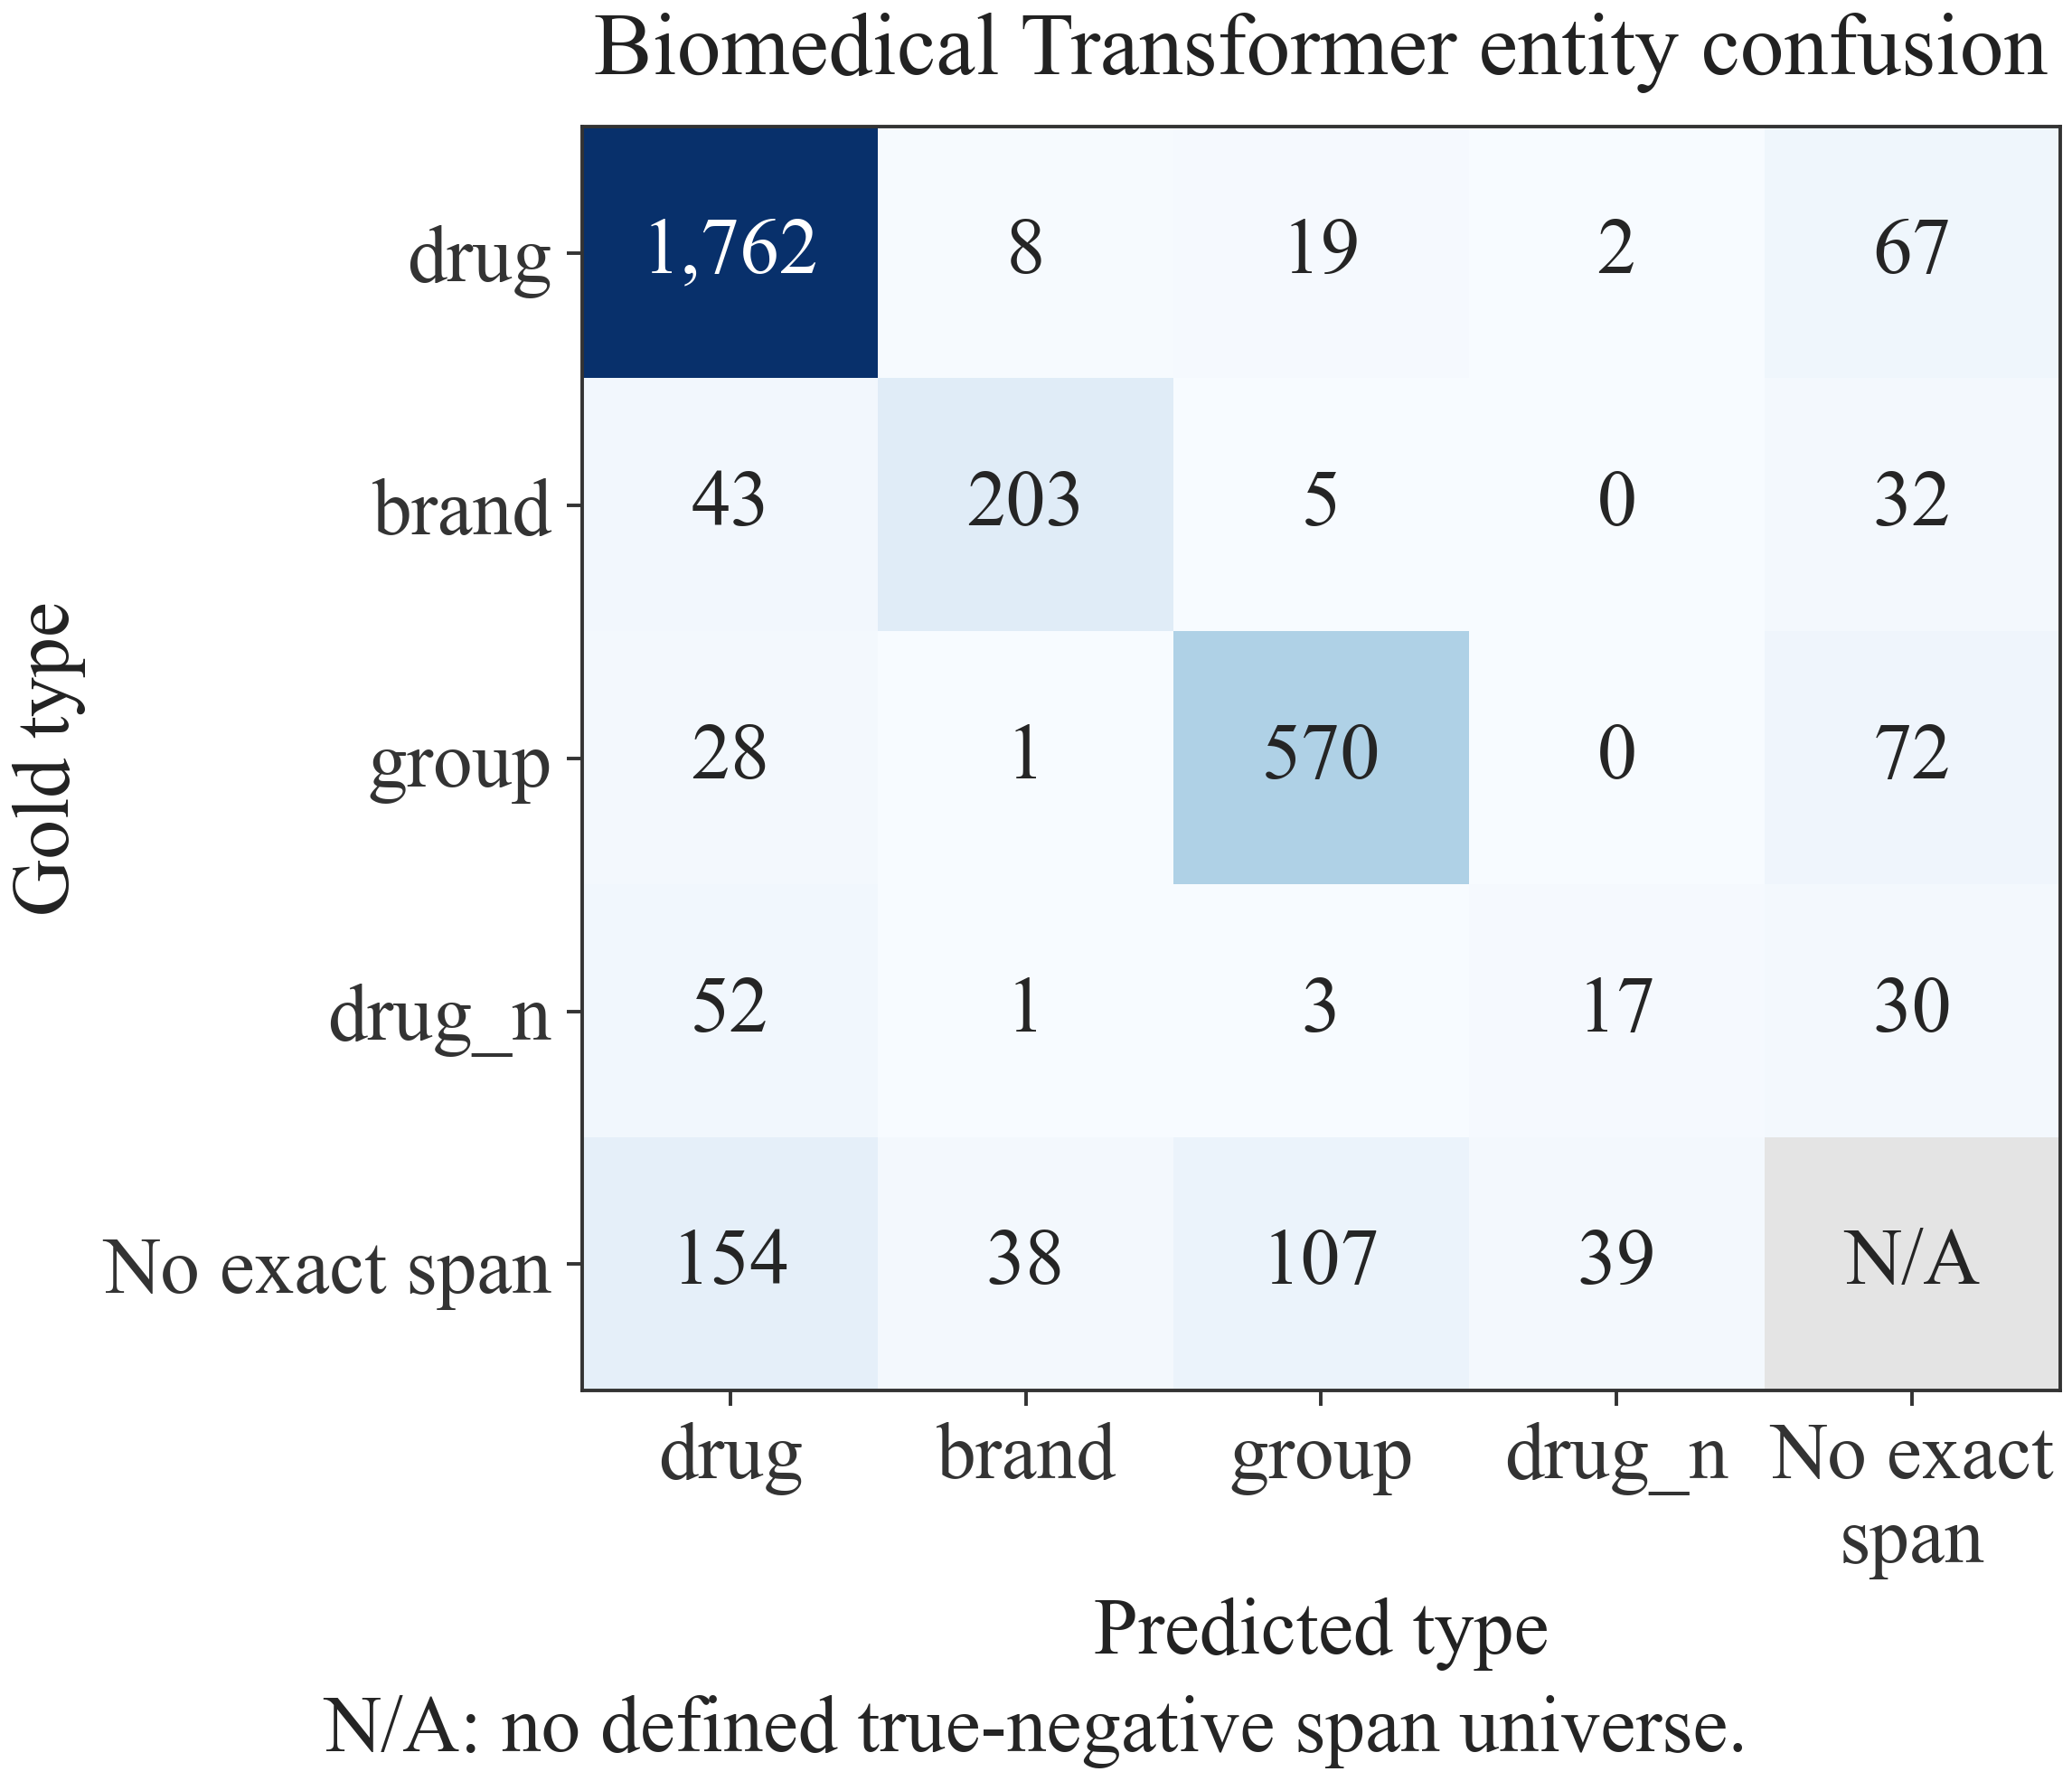

In [23]:
confusion = entity_confusion(gold, predictions["Biomedical Transformer"])
plot_data = confusion.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.55, 5.63), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
matrix = plot_data.pivot(index="Gold type", columns="Predicted type", values="Count")
for axis in ("index", "columns"):
    labels = list(getattr(matrix, axis))
    order = (
        list(ENTITY_TYPES) + ["No exact span"]
        if set(ENTITY_TYPES) <= set(labels)
        else ["O", "B", "I", "E", "S"]
    )
    if set(labels) <= set(order):
        matrix = matrix.reindex(**{axis: [label for label in order if label in labels]})
values = matrix.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
assert not np.isinf(values).any()
signed = bool(len(finite) and finite.min() < 0)
colormap = mpl.colormaps["RdBu_r" if signed else "Blues"].copy()
colormap.set_bad("#E4E4E4")
heatmap = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=colormap,
    aspect="auto",
    **{"vmin": -1, "vmax": 1} if signed else {},
)
short_labels = {
    "Overlong": "Too\nlong",
    "Underlong": "Too\nshort",
    "Shifted overlap": "Shifted",
    "Wrong type": "Wrong\ntype",
}
ax.set_xticks(
    range(len(matrix.columns)),
    [short_labels.get(str(v), textwrap.fill(str(v), 11)) for v in matrix.columns],
)
ax.set_yticks(range(len(matrix)), [textwrap.fill(str(v), 16) for v in matrix.index])
for (row, column), value in np.ndenumerate(values):
    rgba = heatmap.cmap(heatmap.norm(value))
    luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
    if not np.isfinite(value):
        annotation = "N/A"
    elif "Count" == "Count":
        annotation = f"{value:,.0f}"
    elif 0 < abs(value) < 0.005:
        annotation = ">−0.01" if value < 0 else "<0.01"
    else:
        annotation = f"{value:.2f}".replace("-", "−")
    ax.text(
        column,
        row,
        annotation,
        ha="center",
        va="center",
        fontsize=18,
        color="white" if np.isfinite(value) and luminance < 0.5 else INK,
    )
if np.isnan(values).any():
    assert "N/A: no defined true-negative span universe."
    fig.supxlabel(
        textwrap.fill("N/A: no defined true-negative span universe.", 52),
        fontsize=18,
        color=INK,
    )
ax.set_title("Biomedical Transformer entity confusion", fontsize=20, pad=12)
ax.set_xlabel("Predicted type")
ax.set_ylabel("Gold type")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(
    PROJECT_ROOT / "figures/PNG/pub_04_entity_confusion.png", dpi=350, facecolor="white"
)
fig.savefig(
    PROJECT_ROOT / "figures/PDF/pub_04_entity_confusion.pdf", dpi=350, facecolor="white"
)
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_04_entity_confusion_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

The matrix includes type substitutions plus unmatched gold and predicted boundaries.

Four entity types and a No exact span category; counts are entities, not tokens.

An incorrect boundary contributes a missed gold span and an unmatched predicted span.

**Scope.** The No exact span / No exact span corner is not a true-negative count.

## Expert error complementarity

**Scientific question.** Do the Transformer and CRF recover different gold mentions?

In [24]:
def error_complementarity(gold, predictions):
    g = span_set(gold, gold=True)
    rows = []
    for a, b in combinations(predictions, 2):
        pa, pb = (span_set(predictions[a]), span_set(predictions[b]))
        fa, fb = (g - pa, g - pb)
        rows.append(
            {
                "Model A": a,
                "Model B": b,
                "Gold N": len(g),
                "Both missed": len(fa & fb),
                "A only recovered": len((pa & g) - pb),
                "B only recovered": len((pb & g) - pa),
                "Failure Jaccard": len(fa & fb) / max(len(fa | fb), 1),
                "Oracle union recall": len((pa | pb) & g) / len(g),
            }
        )
    return pd.DataFrame(rows)

In [25]:
experts = {
    model: pd.read_parquet(
        PROJECT_ROOT / "Predictions/Validation" / (MODELS[model] + ".parquet")
    )
    for model in ["Linear-chain CRF", "Biomedical Transformer"]
}
expert_data = (sentences, gold, tokens)
complementarity = error_complementarity(expert_data[1], experts)
result_table = complementarity.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_04_error_complementarity.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Model A,Model B,Gold N,Both missed,A only recovered,B only recovered,Failure Jaccard,Oracle union recall
Linear-chain CRF,Biomedical Transformer,2915,202,161,255,0.3269,0.9307


Disjoint recoveries quantify potential headroom for candidate union.

Failure Jaccard and oracle union recall are computed from exact typed gold matches.

Complementarity supports testing a fusion mechanism.

**Scope.** The oracle union uses gold for analysis and is not a deployable decision rule.

## Document-sampling uncertainty

**Scientific question.** How uncertain are frozen-model scores under resampling of development documents?

In [26]:
def holm(values):
    p = np.asarray(values)
    order = np.argsort(p)
    result = np.zeros(len(p))
    result[order] = np.minimum(
        1, np.maximum.accumulate(p[order] * (len(p) - np.arange(len(p))))
    )
    return result

In [27]:
def document_counts(sentences, gold, prediction):
    documents = sorted(sentences.document_id.unique())
    gg = {d: span_set(f, gold=True) for d, f in gold.groupby("document_id")}
    pp = {d: span_set(f) for d, f in prediction.groupby("document_id")}
    values = np.array(
        [
            (
                len(gg.get(d, set()) & pp.get(d, set())),
                len(pp.get(d, set())),
                len(gg.get(d, set())),
            )
            for d in documents
        ],
        dtype=int,
    )
    assert values[:, 1].sum() == len(span_set(prediction))
    return (documents, values)

In [28]:
def clustered_statistics(sentences, gold, predictions, resamples=2000):
    names = list(predictions)
    counts = {m: document_counts(sentences, gold, p)[1] for m, p in predictions.items()}
    n = len(sentences.document_id.unique())
    rng = np.random.default_rng(20260905)
    draws = rng.integers(0, n, size=(resamples, n))
    f1 = lambda c: np.divide(
        2 * c[..., 0],
        c[..., 1] + c[..., 2],
        out=np.zeros(c.shape[:-1]),
        where=c[..., 1] + c[..., 2] > 0,
    )
    boot = {m: f1(c[draws].sum(axis=1)) for m, c in counts.items()}
    rows = [
        {
            "Model": m,
            "N Documents": n,
            "N Gold": len(gold),
            "Typed F1": float(f1(c.sum(0))),
            "CI Low": np.quantile(boot[m], 0.025),
            "CI High": np.quantile(boot[m], 0.975),
            "Resamples": resamples,
        }
        for m, c in counts.items()
    ]
    comparisons = []
    if "ACT-NER" in names:
        for m in [n for n in FOCAL if n != "ACT-NER" and n in names]:
            delta = boot["ACT-NER"] - boot[m]
            comparisons.append(
                {
                    "Comparison": f"ACT-NER vs {m}",
                    "N Documents": n,
                    "Micro-F1 difference": float(
                        f1(counts["ACT-NER"].sum(0)) - f1(counts[m].sum(0))
                    ),
                    "CI Low": np.quantile(delta, 0.025),
                    "CI High": np.quantile(delta, 0.975),
                    "Estimand": "Corpus micro-F1; documents resampled",
                }
            )
    secondary = []
    for m in [n for n in FOCAL if n != "ACT-NER" and n in names and ("ACT-NER" in names)]:
        differences = f1(counts["ACT-NER"]) - f1(counts[m])
        nonzero = differences[np.abs(differences) > 1e-12]
        ranks = stats.rankdata(np.abs(nonzero))
        p = (
            float(stats.wilcoxon(nonzero, zero_method="wilcox", method="auto").pvalue)
            if len(nonzero)
            else 1.0
        )
        secondary.append(
            {
                "Comparison": f"ACT-NER vs {m}",
                "N Documents": n,
                "Nonzero pairs": len(nonzero),
                "Mean document F1 difference": differences.mean(),
                "Median difference": np.median(differences),
                "Rank-biserial effect": (
                    float(np.sum(ranks * np.sign(nonzero)) / ranks.sum())
                    if len(nonzero)
                    else 0.0
                ),
                "p-value": p,
            }
        )
    secondary = pd.DataFrame(secondary)
    if len(secondary):
        secondary["Holm p-value"] = holm(secondary["p-value"])
    return (pd.DataFrame(rows), pd.DataFrame(comparisons), secondary)

In [29]:
intervals, _, _ = clustered_statistics(sentences, gold, predictions, resamples=2000)
result_table = intervals.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_04_document_intervals.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Model,N Documents,N Gold,Typed F1,CI Low,CI High,Resamples
BiLSTM-CRF,142,2915,0.8298,0.7945,0.8617,2000
Biomedical Transformer,142,2915,0.8554,0.8238,0.8827,2000


The bootstrap recomputes corpus micro-F1 after sampling entire documents, including documents without gold.

**Scope.** These intervals are conditional on fitted models and past development selection; they do not repeat optimization.

## Frozen artifact complexity

**Scientific question.** How much storage and how many saved learned coefficients do the frozen models contain?

In [30]:
artifact_rows = []
for model in predictions:
    stem = MODELS[model]
    family = "Comparators" if model in ["BiLSTM-CRF", "Biomedical Transformer"] else "Baselines"
    suffix = ".pt" if family == "Comparators" else ".json" if model == "O-only" else ".joblib"
    artifact = PROJECT_ROOT / "Models" / family / (stem + suffix)
    if suffix == ".pt":
        weights = torch.load(artifact, map_location="cpu", weights_only=False)["state_dict"]
        count = sum(
            (
                value.numel()
                for name, value in weights.items()
                if name.rsplit(".", 1)[-1].startswith(("weight", "bias"))
                or name.rsplit(".", 1)[-1]
                in ("transitions", "start_transitions", "end_transitions")
            )
        )
        definition = "Saved trainable-weight tensors"
    elif model == "Linear-chain CRF":
        estimator = joblib.load(artifact)
        count = len(estimator.state_features_) + len(estimator.transition_features_)
        definition = "Nonzero state/transition coefficients"
    elif model == "Logistic Regression":
        estimator = joblib.load(artifact)["model"]
        count = estimator.coef_.size + estimator.intercept_.size
        definition = "Linear coefficients and intercepts"
    else:
        count, definition = (0, "No optimized numeric weights")
    artifact_rows.append(
        {
            "Model": model,
            "N": len(gold),
            "Coefficients": count,
            "Counting definition": definition,
            "Artifact size (MiB)": artifact.stat().st_size / 2**20,
        }
    )
complexity = pd.DataFrame(artifact_rows)

In [31]:
result_table = complexity.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_04_artifact_complexity.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 3)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Model,N,Coefficients,Counting definition,Artifact size (MiB)
BiLSTM-CRF,2915,3166740,Saved trainable-weight tensors,12.086
Biomedical Transformer,2915,22571921,Saved trainable-weight tensors,86.146


Weight counts and serialized size are derived from the actual frozen artifacts, not a result table.

**Scope.** Definitions differ across model families. Storage is not RAM, VRAM, latency, or training cost.